# **Bank Customer Churn Prediction**

## Project overview

Customer churn is when a customer stops using a bank's services. Keeping existing customers is cheaper than acquiring new ones, so predicting which customers are likely to leave lets a bank act early (for example with targeted offers).

**Goal:** build an end-to-end machine learning pipeline that predicts whether a customer
will leave the bank, from their profile and account details.


In [52]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split
print("All libraries imported successfully!")

All libraries imported successfully!


In [53]:
df=pd.read_csv("data/ChurnModel.csv")

In [54]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [55]:
df.shape

(10000, 14)

**Dataset:** Churn Modelling dataset (Kaggle), 10,000 customers of a European bank,
14 columns. Target column: `Exited` (1 = left the bank, 0 = stayed).

**Dataset Information**

- RowNumber:	The row number in the dataset.
- CustomerId: A unique identification number assigned to each customer.
- Surname:	The customer's last name.
- CreditScore:	A numerical score indicating the customer's creditworthiness.
- Geography:	The country where the customer is located, such as France, Spain, or Germany.
- Gender: The customer's gender.
- Age: The customer's age in years.
- Tenure:	The number of years the customer has been with the bank.
- Balance:	The amount of money in the customer's bank account.
- NumOfProducts:	The number of bank products the customer uses.
- HasCrCard:	Indicates whether the customer has a credit card: 1 = Yes, 0 = No.
- IsActiveMember:	Indicates whether the customer is classified as an active member: 1 = Yes, 0 = No.
- EstimatedSalary:	The estimated annual salary of the customer.
- Exited:	Indicates whether the customer left the bank: 1 = Yes, 0 = No. This is the target variable for predicting customer churn.

In [56]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


In [57]:
df = df.drop(columns=["RowNumber"])

Since the row number is not necessary it was dropped.

In [58]:
df.shape

(10000, 13)

In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerId       10000 non-null  int64  
 1   Surname          10000 non-null  str    
 2   CreditScore      10000 non-null  int64  
 3   Geography        10000 non-null  str    
 4   Gender           10000 non-null  str    
 5   Age              10000 non-null  int64  
 6   Tenure           10000 non-null  int64  
 7   Balance          10000 non-null  float64
 8   NumOfProducts    10000 non-null  int64  
 9   HasCrCard        10000 non-null  int64  
 10  IsActiveMember   10000 non-null  int64  
 11  EstimatedSalary  10000 non-null  float64
 12  Exited           10000 non-null  int64  
dtypes: float64(2), int64(8), str(3)
memory usage: 1015.8 KB


In [60]:
df.isna().sum()

CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [61]:
df.isnull().sum()

CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

No missing values found in the dataset.

In [62]:
df.duplicated().sum()

np.int64(0)

In [63]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [64]:
print("Repeated CustomerID:", df['CustomerId'].duplicated().sum())

Repeated CustomerID: 0


No repeated `CustomerId`. Each row is a unique customer.

Checking the number of unique values of each column

In [65]:
df.nunique()

CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

Checking statistics of the dataset

In [66]:
df.describe()

,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [67]:
for col in ["Geography", "Gender"]:
    print (col, df[col].unique())
    print(df[col].value_counts(), "\n")

Geography <StringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64 

Gender <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Gender
Male      5457
Female    4543
Name: count, dtype: int64 



Geography has 3 clean categories (France, Germany, Spain) and Gender has 2 (Female, Male). No spelling, capitalisation or spacing issues, so no fixes needed. France holds about half the customers, so churn comparisons across countries should use rates rather than counts.

In [68]:
display(df.describe().T)

for col in ["Tenure", "NumOfProducts", "HasCrCard", "IsActiveMember", "Exited"]:
    print(col, sorted(df[col].unique()))

,count,mean,std,min,25%,50%,75%,max
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48
Exited,10000.0,2.037000e-01,0.402769,0.00,0.00,0.000000e+00,0.000000e+00,1.00


Tenure [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
NumOfProducts [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
HasCrCard [np.int64(0), np.int64(1)]
IsActiveMember [np.int64(0), np.int64(1)]
Exited [np.int64(0), np.int64(1)]


**Finding:** all values are within plausible ranges (credit score 350 - 850, age 18-92,
tenure 0-10, products 1-4; binary columns contain only 0 and 1; no negative values).

Points noted:
- 233 customers have a credit score of exactly 850, the top of the scale.
  This looks like a ceiling, not an error. Kept.
- 59 customers have an EstimatedSalary below 1,000 (minimum 11.58). This is
  implausibly low for an annual salary, but the dataset does not define how the
  salary was estimated, so the rows are kept and this is recorded as a limitation.

In [69]:
(df["CreditScore"] == 850).sum()

np.int64(233)

In [70]:
(df["EstimatedSalary"] < 1000).sum()

np.int64(59)

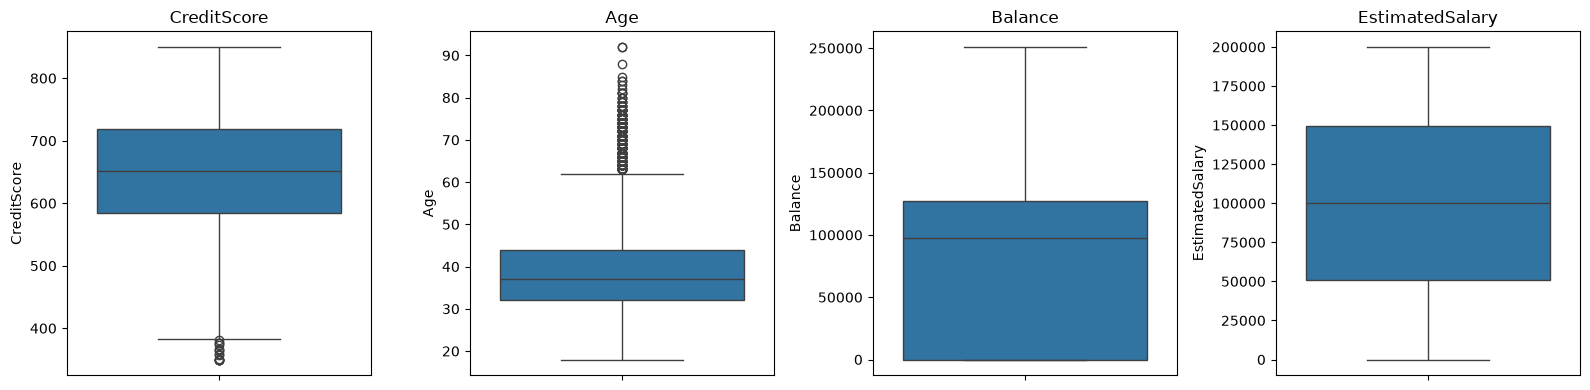

CreditScore: 15 outliers, churn rate among them = 100.0%
Age: 359 outliers, churn rate among them = 20.3%
Balance: 0 outliers, churn rate among them = nan%
EstimatedSalary: 0 outliers, churn rate among them = nan%


In [71]:
num_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary"]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    print(f"{col}: {mask.sum()} outliers, churn rate among them = {df.loc[mask, 'Exited'].mean():.1%}")

**Finding (IQR rule):**
- CreditScore: 15 outliers (very low scores), and all 15 churned (100%).
- Age: 359 outliers (older customers, up to 92), churn rate about 20%, the same
  as the overall rate.
- Balance and EstimatedSalary: no outliers.

**Decision:** keep all outliers. They are realistic values, not errors.
The low credit score customers are a strong churn signal; removing them would
remove information the model needs.

In [72]:
zero = df["Balance"] == 0
print(f"Zero balance: {zero.sum()} customers ({zero.mean():.1%})")
print(df.loc[zero, "Geography"].value_counts())
print(df.groupby(zero)["Exited"].mean())

Zero balance: 3617 customers (36.2%)
Geography
France    2418
Spain     1199
Name: count, dtype: int64
Balance
False    0.240796
True     0.138236
Name: Exited, dtype: float64


**Finding:** 3,617 customers (36.2%) have a balance of exactly 0: 2,418 in France
and 1,199 in Spain, none in Germany. Zero balance customers churn less than
customers with a balance.

**Decision:** keep. They behave like a real customer group rather than missing data.
The absence of zero balances in Germany cannot be explained from the data and
is noted. A `HasZeroBalance` feature may be tested later.

In [73]:
print("Unique surnames:", df["Surname"].nunique())
df = df.drop(columns=["CustomerId", "Surname"])
df.shape

Unique surnames: 2932


(10000, 11)

**Decision:** dropped `CustomerId` and `Surname`.
- `CustomerId` is an account number with no relationship to churn; it was only
  needed for the duplicate check.
- `Surname` has 2,932 unique values. Encoding it would create thousands of
  meaningless columns, and names should not be used to predict customer behaviour.
- 92 surnames contain "?" characters (likely accented letters lost when the file
  was saved). Since the column is dropped, no fix is needed.

In [74]:
df["Exited"].value_counts(normalize=True)

Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64

**Finding:** about 20% of customers churned and 80% stayed, so the classes are imbalanced.

**Implications:**
- Use a stratified train/test split so both sets keep the same ratio.
- Accuracy alone is misleading: predicting "no churn" for everyone would already
  score about 80%. Models will be compared using ROC-AUC, recall and F1.

##### **Cleaning summary**

| Check | Result | Action |
|---|---|---|
| Data types | Correct | None |
| Missing values | None | None |
| Duplicates | None | None |
| Categories | Consistent | None |
| Value ranges | Plausible; 59 very low salary estimates | Kept; noted as limitation |
| Outliers | 15 CreditScore (all churned), 359 Age | Kept (real customers) |
| Zero balances | 36.2%, none in Germany | Kept; possible feature |
| Identifier columns | No predictive value | Dropped RowNumber, CustomerId, Surname |
| Target | ~20% churn | Stratified split; ROC-AUC / recall / F1 |

## Exploratory Data Analysis (EDA)



#### 1. Overall churn rate and target distribution
The overall churn rate is the baseline every group is compared against.
The chart shows the class imbalance found during cleaning.

Overall churn rate: 20.4%


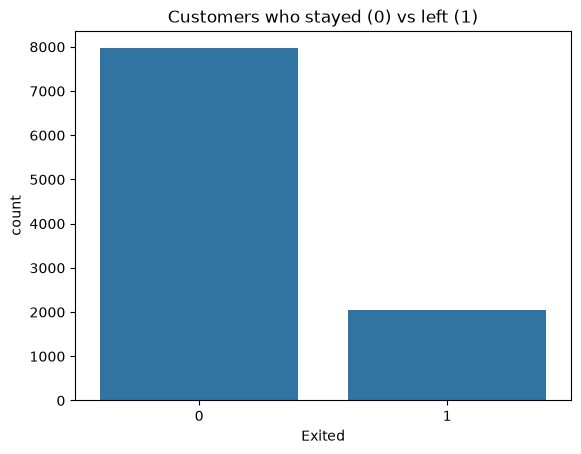

In [75]:
overall_churn = df["Exited"].mean()
print(f"Overall churn rate: {overall_churn:.1%}")

sns.countplot(x="Exited", data=df)
plt.title("Customers who stayed (0) vs left (1)")
plt.show()

#### 2. Churn rate by categorical features
Comparing churn rates across groups shows which customer characteristics
are linked to leaving. The red dashed line is the overall churn rate.

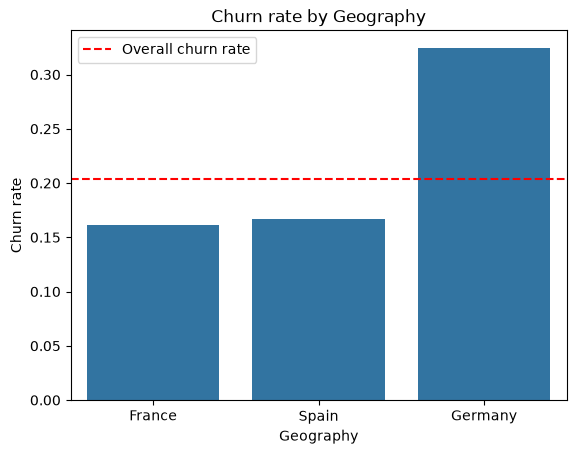

           churn_rate  customers
Geography                       
France          0.162       5014
Germany         0.324       2509
Spain           0.167       2477 



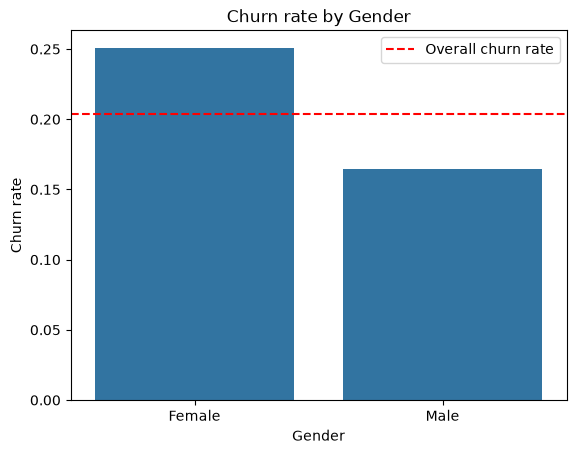

        churn_rate  customers
Gender                       
Female       0.251       4543
Male         0.165       5457 



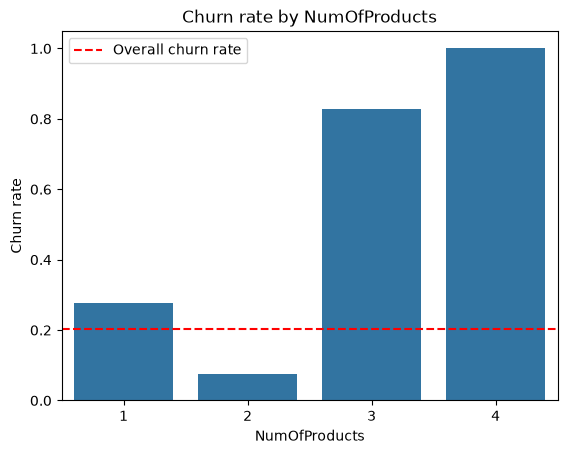

               churn_rate  customers
NumOfProducts                       
1                   0.277       5084
2                   0.076       4590
3                   0.827        266
4                   1.000         60 



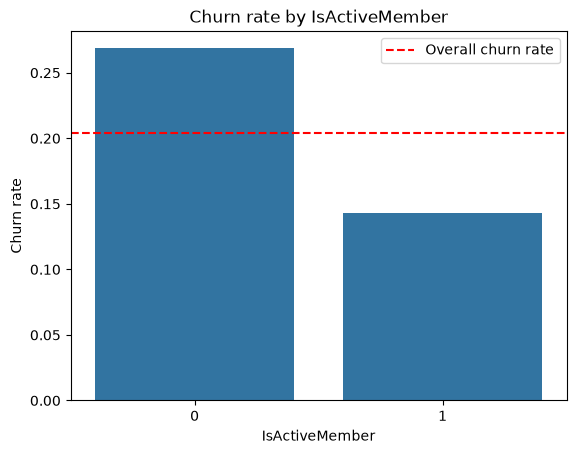

                churn_rate  customers
IsActiveMember                       
0                    0.269       4849
1                    0.143       5151 



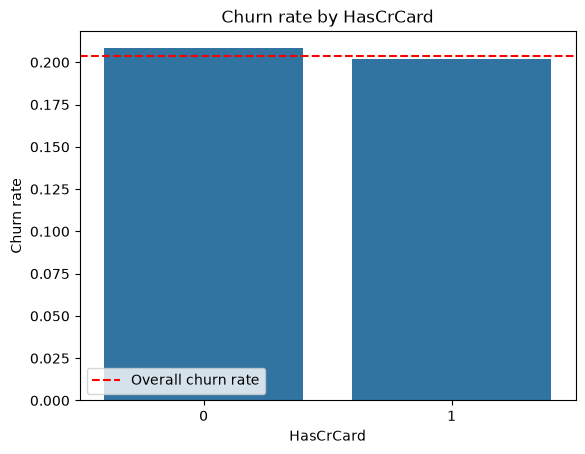

           churn_rate  customers
HasCrCard                       
0               0.208       2945
1               0.202       7055 



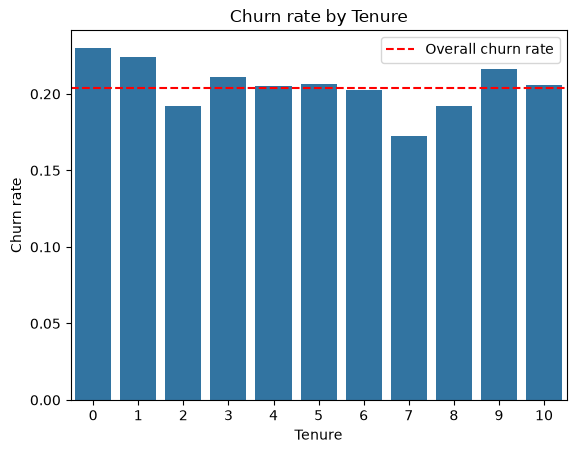

        churn_rate  customers
Tenure                       
0            0.230        413
1            0.224       1035
2            0.192       1048
3            0.211       1009
4            0.205        989
5            0.207       1012
6            0.203        967
7            0.172       1028
8            0.192       1025
9            0.216        984
10           0.206        490 



In [76]:
cat_cols = ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard", "Tenure"]

for col in cat_cols:
    sns.barplot(x=col, y="Exited", data=df, errorbar=None)
    plt.axhline(overall_churn, color="red", linestyle="--", label="Overall churn rate")
    plt.title(f"Churn rate by {col}")
    plt.ylabel("Churn rate")
    plt.legend()
    plt.show()

    print(df.groupby(col)["Exited"].agg(churn_rate="mean", customers="count").round(3), "\n")

**Findings** (overall churn rate = 20.4%):
- **Geography:** Germany has the highest churn rate (32.4%), about double France
  (16.2%) and Spain (16.7%). France and Spain behave almost the same.
- **Gender:** female customers churn more than male customers (25.1% vs 16.5%).
- **NumOfProducts:** strongest and non-linear pattern. Customers with 2 products have
  the lowest churn (7.6%), those with 1 product are above average (27.7%), and churn
  rises sharply at 3 products (82.7%) and 4 products (100%). The 3- and 4-product
  groups are small (266 and 60 customers), so their exact rates should be treated
  with caution, but the pattern is very strong.
- **IsActiveMember:** inactive customers churn almost twice as often as active
  customers (26.9% vs 14.3%).
- **HasCrCard:** no meaningful difference (20.8% vs 20.2%), both at the overall rate.
  This feature is unlikely to help the model much.
- **Tenure:** churn stays between about 17% and 23% across all years with no clear
  trend, so tenure appears to have little effect on churn.


#### 3. Numeric features: customers who left vs stayed

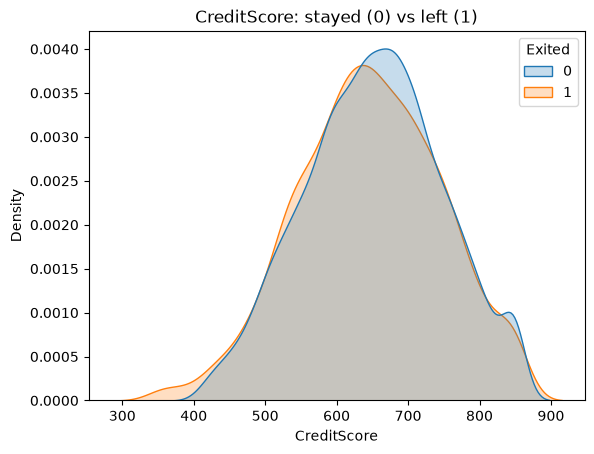

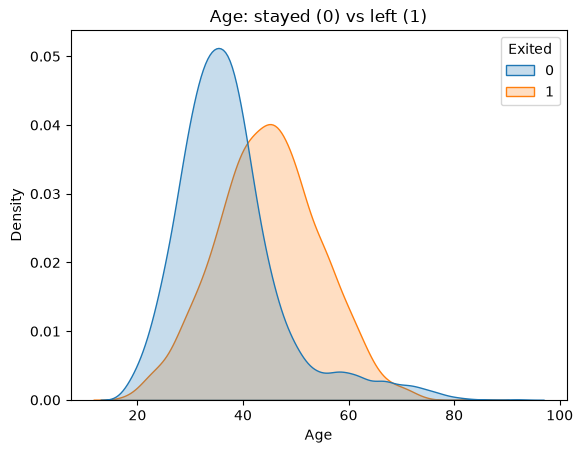

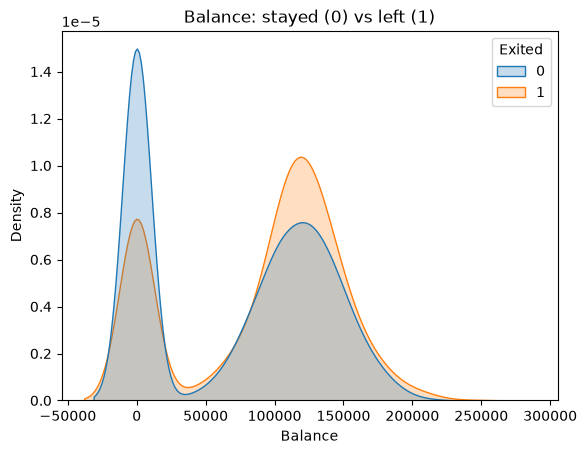

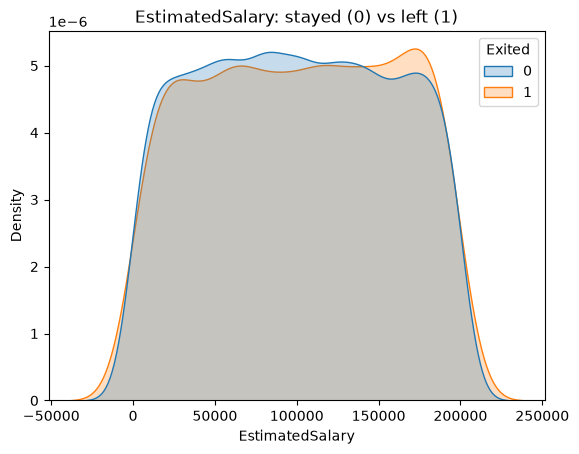

        CreditScore   Age   Balance  EstimatedSalary
Exited                                              
0             653.0  36.0   92072.7          99645.0
1             646.0  45.0  109349.3         102460.8


In [77]:
num_cols = ["CreditScore", "Age", "Balance", "EstimatedSalary"]

for col in num_cols:
    sns.kdeplot(data=df, x=col, hue="Exited", common_norm=False, fill=True)
    plt.title(f"{col}: stayed (0) vs left (1)")
    plt.show()

print(df.groupby("Exited")[num_cols].median().round(1))

**Findings:**
- **Age:** strongest separation of the four. Customers who left are older
  (median 45) than those who stayed (median 36). Stayers peak in their mid-30s,
  leavers in their mid-40s. Age is likely to be one of the most important features.
- **Balance:** two clear groups: zero balance and roughly 100,000-150,000.
  Stayers are more concentrated at zero; leavers are more concentrated in the
  higher balance range (median 109,349 vs 92,073). Customers holding money with
  the bank appear more likely to leave.
- **CreditScore:** distributions almost fully overlap (median 646 vs 653).
  The only difference is a small tail of leavers below ~400, matching the
  15 low-score customers found during cleaning, all of whom churned.
- **EstimatedSalary:** no meaningful difference (median 102,461 vs 99,645);
  the distributions are nearly identical. Salary is unlikely to help the model.

#### 4. Churn rate by age group
Age bands give a clear churn rate per life stage, which is easier to
explain to a business audience than a continuous curve.

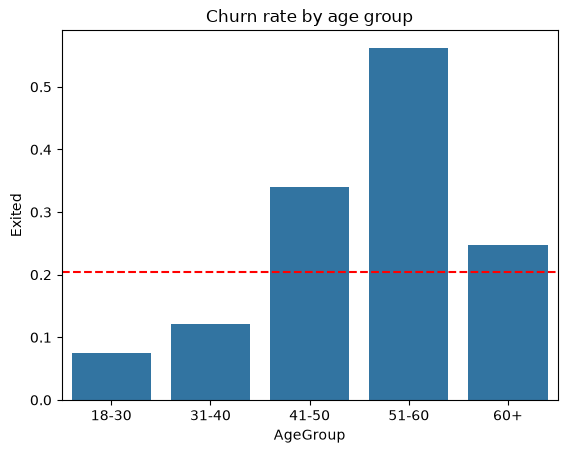

          churn_rate  customers
AgeGroup                       
18-30          0.075       1968
31-40          0.121       4451
41-50          0.340       2320
51-60          0.562        797
60+            0.248        464


In [80]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100],
  labels=["18-30", "31-40", "41-50", "51-60", "60+"])

sns.barplot(x="AgeGroup", y="Exited", data=df, errorbar=None)
plt.axhline(overall_churn, color="red", linestyle="--")
plt.title("Churn rate by age group")
plt.show()

print(df.groupby("AgeGroup", observed=True)["Exited"].agg(churn_rate="mean", customers="count").round(3))

**Findings:**
- Churn rises sharply with age up to 60: 7.5% (18-30), 12.1% (31-40),
  34.0% (41-50) and 56.2% (51-60).
- The biggest jump is after 40: churn nearly triples from the 31-40 group
  to the 41-50 group.
- The 51-60 group has the highest churn rate (56.2%, 797 customers),
  more than 2.5 times the overall rate.
- Churn drops again for customers over 60 (24.8%), though this is the
  smallest group (464 customers). The data does not show why.
- Customers aged 41-60 (3,117 customers) are the main high-risk segment.

#### 5. Zero-balance customers
Cleaning found that 36.2% of customers have a zero balance, none of
them in Germany. This step measures how that group behaves.

In [81]:
df["HasZeroBalance"] = (df["Balance"] == 0).astype(int)

print(df.groupby("HasZeroBalance")["Exited"].agg(churn_rate="mean", customers="count").round(3))
print()
print(pd.crosstab(df["Geography"], df["HasZeroBalance"]))

                churn_rate  customers
HasZeroBalance                       
0                    0.241       6383
1                    0.138       3617

HasZeroBalance     0     1
Geography                 
France          2596  2418
Germany         2509     0
Spain           1278  1199


In [82]:
fr_es = df[df["Geography"].isin(["France", "Spain"])]
print(fr_es.groupby(["Geography", "HasZeroBalance"])["Exited"].agg(churn_rate="mean", customers="count").round(3))

                          churn_rate  customers
Geography HasZeroBalance                       
France    0                    0.182       2596
          1                    0.139       2418
Spain     0                    0.196       1278
          1                    0.136       1199


**Findings:**
- Customers with a balance churn more (24.1%, 6,383 customers) than
  zero-balance customers (13.8%, 3,617 customers).
- Zero balances exist only in France (2,418, about 48% of French customers)
  and Spain (1,199, about 48%). No German customer has a zero balance.
- Because Germany has the highest churn rate (32.4%) and all German customers
  have a balance, part of this difference could come from Germany. Comparing
  within France and Spain only:
  - France: 18.2% (balance) vs 13.9% (zero)
  - Spain: 19.6% (balance) vs 13.6% (zero)
- **Conclusion:** the balance effect is real, as it appears within both countries,
  but it is smaller (about 4-6 percentage points) than the overall comparison
  suggests (about 10 points). Part of the overall gap was driven by Germany.
  Geography and balance both matter, and they overlap.

#### 6. Combined effects
Features can interact. A combination of factors may carry much higher
risk than either factor alone.

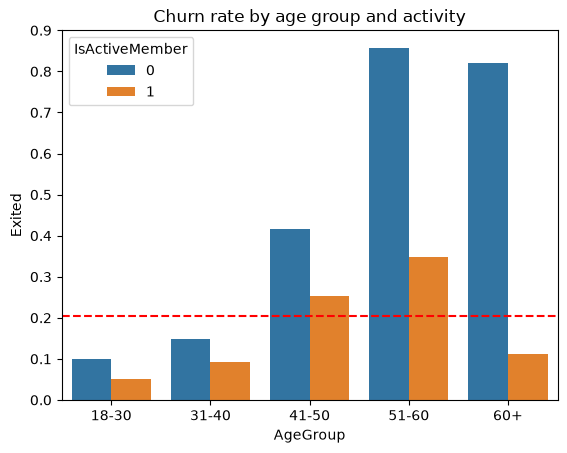

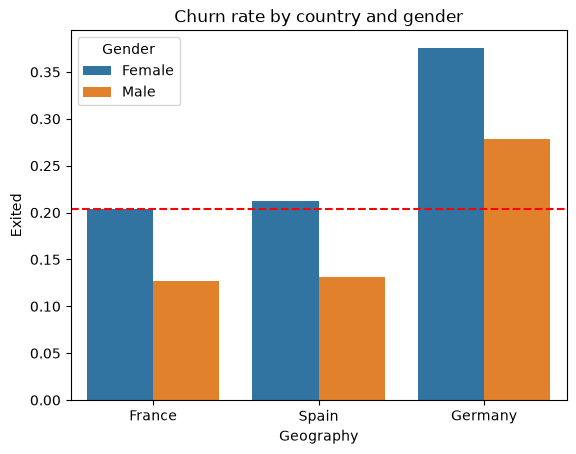

In [83]:
sns.barplot(x="AgeGroup", y="Exited", hue="IsActiveMember", data=df, errorbar=None)
plt.axhline(overall_churn, color="red", linestyle="--")
plt.title("Churn rate by age group and activity")
plt.show()

sns.barplot(x="Geography", y="Exited", hue="Gender", data=df, errorbar=None)
plt.axhline(overall_churn, color="red", linestyle="--")
plt.title("Churn rate by country and gender")
plt.show()

In [84]:
print(df.groupby(["AgeGroup", "IsActiveMember"], observed=True)["Exited"].agg(churn_rate="mean", customers="count").round(3))
print()
print(df.groupby(["Geography", "Gender"])["Exited"].agg(churn_rate="mean", customers="count").round(3))

                         churn_rate  customers
AgeGroup IsActiveMember                       
18-30    0                    0.101        962
         1                    0.051       1006
31-40    0                    0.149       2236
         1                    0.092       2215
41-50    0                    0.416       1226
         1                    0.254       1094
51-60    0                    0.857        336
         1                    0.347        461
60+      0                    0.820         89
         1                    0.112        375

                  churn_rate  customers
Geography Gender                       
France    Female       0.203       2261
          Male         0.127       2753
Germany   Female       0.376       1193
          Male         0.278       1316
Spain     Female       0.212       1089
          Male         0.131       1388


**Findings:**

*Age group × activity: strong interaction*
- Inactive customers churn more than active ones at every age, but the gap grows
  sharply with age: about 5 points for 18-30, 16 points for 41-50,
  51 points for 51-60 and 71 points for 60+.
- Inactive customers aged 51-60 (85.7%, 336 customers) and over 60
  (82.0%, 89 customers) are the highest-risk groups in the dataset.
- Active customers over 60 churn at only 11.2%. Since most over-60s are active
  (375 of 464), this explains why the 60+ group as a whole has lower churn
  than the 51-60 group.

*Country × gender: mostly independent*
- Women churn more than men in every country, with a similar gap of about
  8-10 points (France 20.3% vs 12.7%, Spain 21.2% vs 13.1%,
  Germany 37.6% vs 27.8%).
- The gender gap does not change much between countries, so the two features
  appear to act independently.
- The Germany effect is strong: German men (27.8%) churn more than women
  in France or Spain.

#### 7. Correlation between numeric features
The Exited row shows which numeric features move with churn. The other
cells show whether any features are near-duplicates of each other.
**Limitation:** correlation only measures straight-line relationships, so a
feature with a curved pattern can look weak here even if it matters.

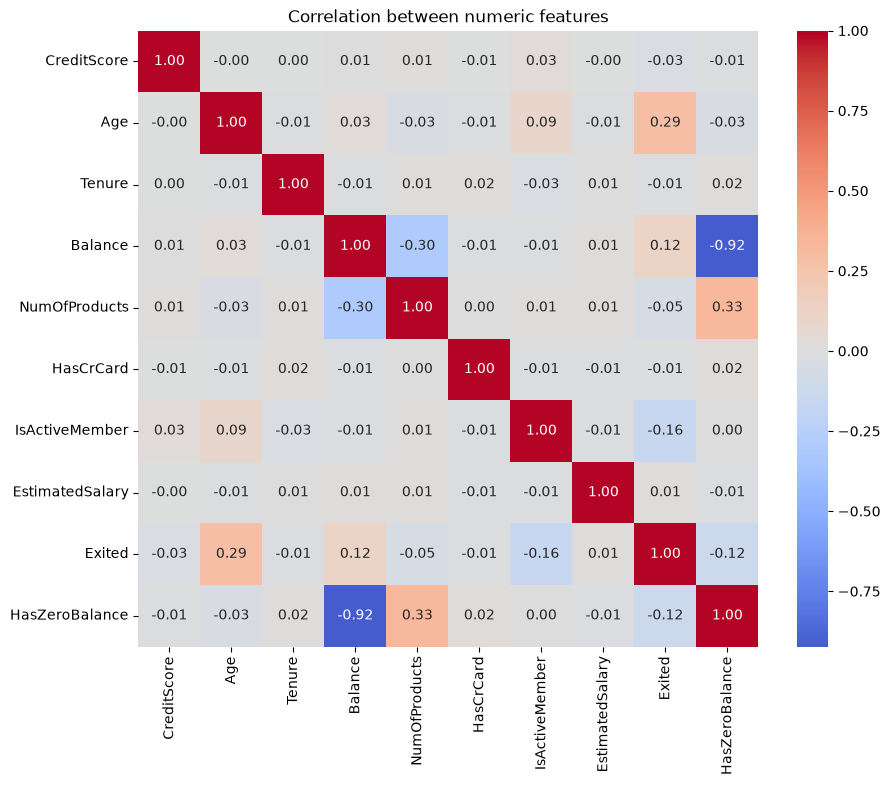

In [85]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

**Findings:**
- Correlation with churn (Exited): Age is the strongest (+0.29), followed by
  IsActiveMember (-0.16), Balance (+0.12) and HasZeroBalance (-0.12).
  CreditScore, Tenure, HasCrCard and EstimatedSalary are close to 0.
- NumOfProducts shows only -0.05, even though step 2 found it to be one of the
  strongest churn signals. Its pattern is non-linear (churn falls from 1 to 2
  products, then rises sharply), which correlation cannot capture. This shows why
  churn rates by group were checked rather than relying on correlation alone.
- Between features, the only strong correlation is Balance vs HasZeroBalance
  (-0.92), which is expected since one is derived from the other. No other
  features overlap strongly.
- Geography and Gender are not included because they are text columns;
  they were analysed earlier.

### Key insights

Overall, about 20% of customers left the bank.

1. **Age is the strongest single driver.** Churn rises from 7.5% (18-30) to 56.2%
   (51-60). Customers aged 41-60 are the main high-risk segment.
2. **Inactivity multiplies age risk.** Inactive customers aged 51-60 churned at 85.7%,
   compared with 34.7% for active customers of the same age. The gap between
   inactive and active customers grows with age.
3. **Number of products has a non-linear effect.** Customers with 2 products churn
   least (7.6%), while those with 3 or 4 products churn at 82.7% and 100%
   (small groups of 266 and 60 customers).
4. **Germany has double the churn of France and Spain** (32.4% vs about 16-17%).
5. **Women churn more than men** in every country (about 8-10 points higher).
6. **Customers holding a balance churn more** than zero-balance customers. Part of
   the overall gap is due to Germany (where every customer has a balance), but a
   4-6 point gap remains within France and Spain.
7. **Credit score, tenure, salary and credit card ownership show little effect**
   on churn.

**Implications for modelling:**
- Several key patterns are non-linear (age, number of products) or depend on
  combinations (age × activity), so tree-based models are expected to
  outperform linear models.
- Classes are imbalanced (about 20% churn), so models will be evaluated with
  ROC-AUC, recall and F1 rather than accuracy alone.